# <span style="color: #070c91;">Import Libraries</span>

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# <span style="color: #070c91;">Dataset Creation</span>

In [5]:
np.random.seed(42)
n = 200

distance = np.random.randint(10, 501, n)
shipment_volume = np.random.randint(10, 201, n)
traffic_level = np.random.randint(1, 6, n)
weather_delay = np.random.choice([0, 0, 0, 1, 2], n)

transport_cost = (
    100
    + distance * 4
    + shipment_volume * 1.8
    + np.random.normal(0, 100, n)
)

delivery_time = (
    1.5
    + distance / 70
    + traffic_level * 0.45
    + weather_delay * 0.8
    + np.random.normal(0, 1.0, n)
)

delivery_time = np.maximum(delivery_time, 0.5)

df = pd.DataFrame({
    "Shipment_ID": range(2001, 2001 + n),
    "Distance_KM": distance,
    "Shipment_Volume": shipment_volume,
    "Traffic_Level": traffic_level,
    "Weather_Delay_Hours": weather_delay,
    "Transport_Cost": transport_cost.round(2),
    "Delivery_Time_Hours": delivery_time.round(2)
})

df.to_csv("week4_logistics_data.csv", index=False)

print("Dataset created successfully!")
print("Dataset shape:", df.shape)
display(df.head(10))


Dataset created successfully!
Dataset shape: (200, 7)


,Shipment_ID,Distance_KM,Shipment_Volume,Traffic_Level,Weather_Delay_Hours,Transport_Cost,Delivery_Time_Hours
0,2001,112,38,1,0,771.52,3.66
1,2002,445,45,5,1,1972.57,11.63
2,2003,358,22,5,0,1689.53,9.35
3,2004,280,169,1,2,1530.95,7.77
4,2005,116,80,5,0,914.07,4.62
5,2006,81,196,3,0,952.33,4.48
6,2007,198,95,4,0,1038.10,8.01
7,2008,30,37,1,1,383.76,4.52
8,2009,112,75,4,1,747.54,7.29
9,2010,131,179,5,2,1083.06,6.71


# <span style="color: #070c91;">Dataset Inspection</span>

In [6]:
print("Dataset information:")
df.info()

print("\nSummary statistics:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 7 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Shipment_ID          200 non-null    int64  
 1   Distance_KM          200 non-null    int32  
 2   Shipment_Volume      200 non-null    int32  
 3   Traffic_Level        200 non-null    int32  
 4   Weather_Delay_Hours  200 non-null    int64  
 5   Transport_Cost       200 non-null    float64
 6   Delivery_Time_Hours  200 non-null    float64
dtypes: float64(2), int32(3), int64(2)
memory usage: 8.7 KB

Summary statistics:


,Shipment_ID,Distance_KM,Shipment_Volume,Traffic_Level,Weather_Delay_Hours,Transport_Cost,Delivery_Time_Hours
count,200.000000,200.00000,200.0000,200.000000,200.000000,200.000000,200.000000
mean,2100.500000,259.08500,112.8550,2.995000,0.715000,1334.917200,7.107550
std,57.879185,140.97948,54.3206,1.464822,0.852885,582.182041,2.420931
min,2001.000000,11.00000,11.0000,1.000000,0.000000,115.430000,1.670000
25%,2050.750000,143.00000,62.7500,2.000000,0.000000,906.112500,5.035000
50%,2100.500000,261.50000,122.0000,3.000000,0.000000,1312.940000,7.590000
75%,2150.250000,376.00000,157.0000,4.000000,2.000000,1831.032500,8.852500
max,2200.000000,499.00000,199.0000,5.000000,2.000000,2442.040000,12.790000



Missing values:
Shipment_ID            0
Distance_KM            0
Shipment_Volume        0
Traffic_Level          0
Weather_Delay_Hours    0
Transport_Cost         0
Delivery_Time_Hours    0
dtype: int64

Duplicate rows:
0


# <span style="color: #070c91;">Split Data into Training & Testing Sets and Train Linear & Regression Model</span>

In [7]:
# Step 4: Prepare features and target
X = df[
    [
        "Distance_KM",
        "Shipment_Volume",
        "Traffic_Level",
        "Weather_Delay_Hours",
        "Transport_Cost"
    ]
]

y = df["Delivery_Time_Hours"]

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
print("Training records:", len(X_train))
print("Testing records:", len(X_test))

# Train Linear Regression model
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# Train Decision Tree model
tree_model = DecisionTreeRegressor(
    max_depth=5,
    random_state=42
)
tree_model.fit(X_train, y_train)

print("\nBoth models trained successfully!")


Training records: 160
Testing records: 40

Both models trained successfully!


# <span style="color: #070c91;">Comparision Between Both Models</span>

In [11]:
# Step 5: Evaluate both models
models = {
    "Linear Regression": linear_model,
    "Decision Tree": tree_model
}

results = []

for name, model in models.items():
    predictions = model.predict(X_test)

    mae = mean_absolute_error(y_test, predictions)
    rmse = np.sqrt(mean_squared_error(y_test, predictions))
    r2 = r2_score(y_test, predictions)

    results.append({
        "Model": name,
        "MAE": round(mae, 3),
        "RMSE": round(rmse, 3),
        "R2 Score": round(r2, 3)
    })

results_df = pd.DataFrame(results)

print("Model Performance Comparison:")
display(results_df)

Model Performance Comparison:


,Model,MAE,RMSE,R2 Score
0,Linear Regression,0.877,1.059,0.823
1,Decision Tree,1.042,1.272,0.745


# <span style="color: #070c91;">Cross Validation Between Both Models</span>

In [12]:
# 5-fold cross-validation using negative MAE
for name, model in models.items():
    cv_scores = cross_val_score(
        model,
        X,
        y,
        cv=5,
        scoring="neg_mean_absolute_error"
    )

    mae_scores = -cv_scores

    print(f"{name}")
    print("Fold MAE scores:", np.round(mae_scores, 3))
    print("Average CV MAE:", round(mae_scores.mean(), 3))
    print("-" * 40)

Linear Regression
Fold MAE scores: [0.874 0.766 0.738 0.93  0.615]
Average CV MAE: 0.785
----------------------------------------
Decision Tree
Fold MAE scores: [1.192 0.93  0.973 1.346 1.301]
Average CV MAE: 1.148
----------------------------------------


# <span style="color: #070c91;"> Result Analysis </span>

### <span style="color: #070c91;">Metric	        Linear Regression	Decision Tree	Better model </span>
#### <span style="color: #3660f7;">MAE	        0.877	            1.042	        Linear Regression </span>
#### <span style="color: #3660f7;">RMSE	        1.059	            1.272	        Linear Regression </span>
#### <span style="color: #3660f7;">R² Score	    0.823	            0.745	        Linear Regression </span>
#### <span style="color: #3660f7;">Average CV MAE	0.785	            1.148	        Linear Regression </span>

### <span style="color: #070c91;"> MAE = 0.877 hours: Test data par average absolute prediction error lagbhag 53 minutes hai. </span>
### <span style="color: #070c91;"> RMSE = 1.059 hours: Badi prediction errors ko zyada weight dene par error lagbhag 1.06 hours hai. </span>
### <span style="color: #070c91;"> R² = 0.823: Model test set mein delivery-time variation ka lagbhag 82.3% explain karta hai. </span>
### <span style="color: #070c91;"> Cross-validation: Linear Regression ka average MAE 0.785 hours hai, jo Decision Tree ke 1.148 hours se kam hai </span>

# <span style="color: #070c91;">Actual vs Predicted Delivery Time Graph</span>

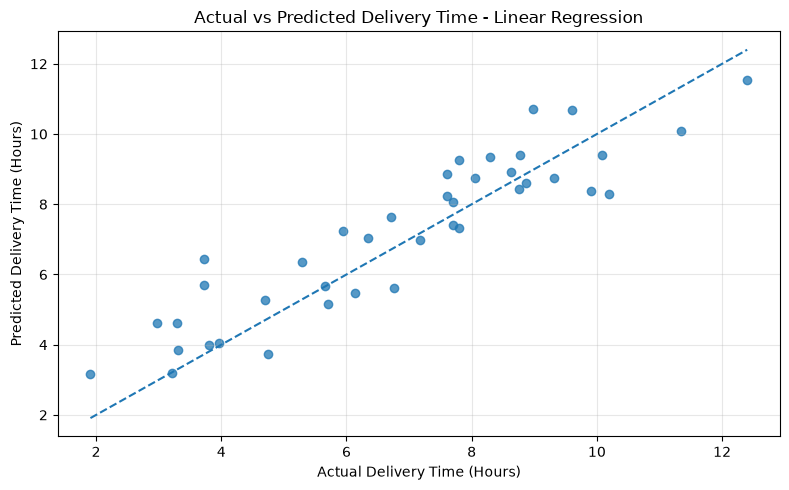

In [13]:
# Step 8: Actual vs Predicted visualization
y_pred = linear_model.predict(X_test)

plt.figure(figsize=(8, 5))
plt.scatter(y_test, y_pred, alpha=0.75)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Delivery Time (Hours)")
plt.ylabel("Predicted Delivery Time (Hours)")
plt.title("Actual vs Predicted Delivery Time - Linear Regression")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("week4_actual_vs_predicted.png", dpi=300)
plt.show()

# <span style="color: #070c91;">Model coefficients and optimization insights</span>

In [14]:
# Step 9: Analyze model coefficients
coefficients_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": linear_model.coef_
})

coefficients_df["Absolute_Coefficient"] = (
    coefficients_df["Coefficient"].abs()
)

coefficients_df = coefficients_df.sort_values(
    "Absolute_Coefficient",
    ascending=False
)

display(coefficients_df)

print("Intercept:", round(linear_model.intercept_, 3))


,Feature,Coefficient,Absolute_Coefficient
3,Weather_Delay_Hours,0.761322,0.761322
2,Traffic_Level,0.530475,0.530475
0,Distance_KM,0.010568,0.010568
4,Transport_Cost,0.000825,0.000825
1,Shipment_Volume,-0.000292,0.000292


Intercept: 1.227


# <span style="color: #070c91;"> Output save </span>

In [16]:
# Save predictions and model comparison
predictions_df = pd.DataFrame({
    "Actual_Delivery_Time": y_test.values,
    "Predicted_Delivery_Time": y_pred.round(2),
    "Prediction_Error": (y_test.values - y_pred).round(2)
})

predictions_df.to_csv(
    "week4_delivery_time_predictions.csv",
    index=False
)

results_df.to_csv(
    "week4_model_comparison.csv",
    index=False
)

coefficients_df.to_csv(
    "week4_model_coefficients.csv",
    index=False
)

print("All Data Saved Successfully")


All data Saved
